# 5. Comparing the four growth models

| Model | Formula | What stays constant | Long-run behaviour | Typical context |
|---|---|---|---|---|
| Linear | $y = a + bt$ | differences $\Delta y$ | grows without bound, steadily | savings, constant-speed travel |
| Exponential | $y = y_0 e^{rt}$ | ratios $y_{t+1}/y_t$ | grows without bound, ever faster (or decays to 0) | early epidemics, compound interest, radioactive decay |
| Logarithmic | $y = a + b\ln t$ | $\Delta y$ per *doubling* of $t$ | grows without bound, ever more slowly | learning curves, decibels, pH |
| Logistic | $y = K/(1+e^{-r(t-t_0)})$ | growth is fastest at $y = K/2$ | levels off at $K$ | limited populations, rumours, saturation |

This notebook puts the four side by side and asks a practical question: **given noisy data, can we tell which model generated it?** All data is **simulated**, so we know the answer and can measure how often we get it right.

**Contents**
1. The four models side by side
2. Diagnostic tests: which quantity is constant?
3. One dataset per model, fitted with all four models
4. Simulation study: how often does model selection pick the right model?
5. Using your own data
6. Exercises

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
rng = np.random.default_rng(2026)

## 1. The four models side by side

Parameters are chosen so that all four curves rise from about the same start to about the same end over $t = 1,\dots,20$, which makes them easy to confuse in a short window.

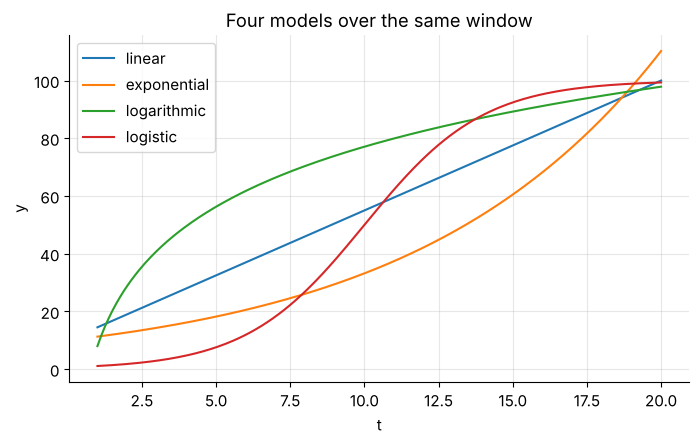

In [2]:
def linear(t, a, b):
    return a + b * t

def exponential(t, y0, r):
    return y0 * np.exp(r * t)

def logarithmic(t, a, b):
    return a + b * np.log(t)

def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

TRUE = {
    "linear":      (linear,      (10.0, 4.5)),
    "exponential": (exponential, (10.0, 0.12)),
    "logarithmic": (logarithmic, (8.0, 30.0)),
    "logistic":    (logistic,    (100.0, 0.5, 10.0)),
}

t = np.linspace(1, 20, 300)
fig, ax = plt.subplots()
for name, (f, params) in TRUE.items():
    ax.plot(t, f(t, *params), label=name)
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.set_title("Four models over the same window")
ax.legend()
plt.show()

## 2. Diagnostic tests: which quantity is constant?

For noise-free series sampled at equal time steps, a quick diagnostic table shows the signature of each model: first differences $\Delta y$, ratios $y_{t+1}/y_t$, and (for the logarithmic model) the change in $y$ when $t$ doubles.

In [3]:
t_int = np.arange(1, 21)
rows = {}
for name, (f, params) in TRUE.items():
    y = f(t_int, *params)
    d = np.diff(y)
    ratio = y[1:] / y[:-1]
    # for the doubling test use t = 1, 2, 4, 8, 16
    t_dbl = np.array([1, 2, 4, 8, 16])
    dbl = np.diff(f(t_dbl, *params))
    rows[name] = {
        "Δy range (min–max)": f"{d.min():.2f} – {d.max():.2f}",
        "ratio range (min–max)": f"{ratio.min():.3f} – {ratio.max():.3f}",
        "Δy per doubling of t": ", ".join(f"{v:.1f}" for v in dbl),
    }
print(pd.DataFrame(rows).T.to_string())

            Δy range (min–max) ratio range (min–max)    Δy per doubling of t
linear             4.50 – 4.50         1.047 – 1.310    4.5, 9.0, 18.0, 36.0
exponential       1.44 – 12.46         1.127 – 1.127    1.4, 3.4, 10.0, 42.1
logarithmic       1.54 – 20.79         1.016 – 3.599  20.8, 20.8, 20.8, 20.8
logistic          0.43 – 12.25         1.004 – 1.637    0.7, 2.9, 22.2, 68.4


How to read it:
- **Linear:** $\Delta y$ has a tiny range (constant).
- **Exponential:** the ratio has a tiny range (constant).
- **Logarithmic:** $\Delta y$ per doubling of $t$ is constant.
- **Logistic:** none of the three is constant; $\Delta y$ rises then falls.

## 3. One dataset per model, fitted with all four models

We generate one noisy dataset from each true model (additive noise, standard deviation 3) and fit every model to it. Fit quality is judged by the **residual sum of squares** (RSS) and by **AIC**, which penalises the extra parameter of the logistic model: $\text{AIC} = n\ln(\text{RSS}/n) + 2k$. Lower AIC is better.

In [4]:
def fit_all(tt, yy):
    # Fit the four models to (tt, yy). Returns {name: (params, rss, k)} (None if a fit failed).
    out = {}
    n = tt.size

    p = np.polyfit(tt, yy, 1)
    out["linear"] = ((p[1], p[0]), np.sum((yy - linear(tt, p[1], p[0])) ** 2), 2)

    # exponential: start from a log-linear fit on positive values, then refine
    pos = yy > 1e-3
    if pos.sum() >= 3:
        s = stats.linregress(tt[pos], np.log(yy[pos]))
        p0 = [np.exp(s.intercept), s.slope]
    else:
        p0 = [yy.max() / 2, 0.05]
    try:
        p, _ = curve_fit(exponential, tt, yy, p0=p0, maxfev=20000)
        out["exponential"] = (tuple(p), np.sum((yy - exponential(tt, *p)) ** 2), 2)
    except (RuntimeError, ValueError, FloatingPointError):
        out["exponential"] = None

    s = stats.linregress(np.log(tt), yy)
    out["logarithmic"] = ((s.intercept, s.slope), np.sum((yy - logarithmic(tt, s.intercept, s.slope)) ** 2), 2)

    try:
        p, _ = curve_fit(
            logistic, tt, yy, p0=[max(yy.max() * 1.1, 1.0), 0.3, float(np.median(tt))],
            bounds=([1.0, 0.001, -50.0], [1e4, 5.0, 100.0]), maxfev=20000,
        )
        out["logistic"] = (tuple(p), np.sum((yy - logistic(tt, *p)) ** 2), 3)
    except (RuntimeError, ValueError):
        out["logistic"] = None
    return out

def aic(rss, n, k):
    return n * np.log(rss / n) + 2 * k

tt = np.arange(1, 21, dtype=float)
sigma = 3.0
example_data = {}
for name, (f, params) in TRUE.items():
    example_data[name] = f(tt, *params) + rng.normal(0, sigma, tt.size)

rows = []
for true_name, yy in example_data.items():
    fits = fit_all(tt, yy)
    for model, res in fits.items():
        if res is None:
            continue
        params, rss, k = res
        rows.append({"data from": true_name, "fitted model": model, "RSS": rss, "AIC": aic(rss, tt.size, k)})
table = pd.DataFrame(rows)
best = table.loc[table.groupby("data from")["AIC"].idxmin()]
print(table.pivot(index="data from", columns="fitted model", values="AIC").round(1).to_string())
print()
print("Best model by AIC for each dataset:")
print(best[["data from", "fitted model"]].to_string(index=False))

fitted model  exponential  linear  logarithmic  logistic
data from                                               
exponential          42.8    91.6        118.3      44.8
linear               76.1    34.8         91.4      44.2
logarithmic         105.9    98.2         53.3      70.0
logistic            117.3    93.8        119.9      49.4

Best model by AIC for each dataset:
  data from fitted model
exponential  exponential
     linear       linear
logarithmic  logarithmic
   logistic     logistic


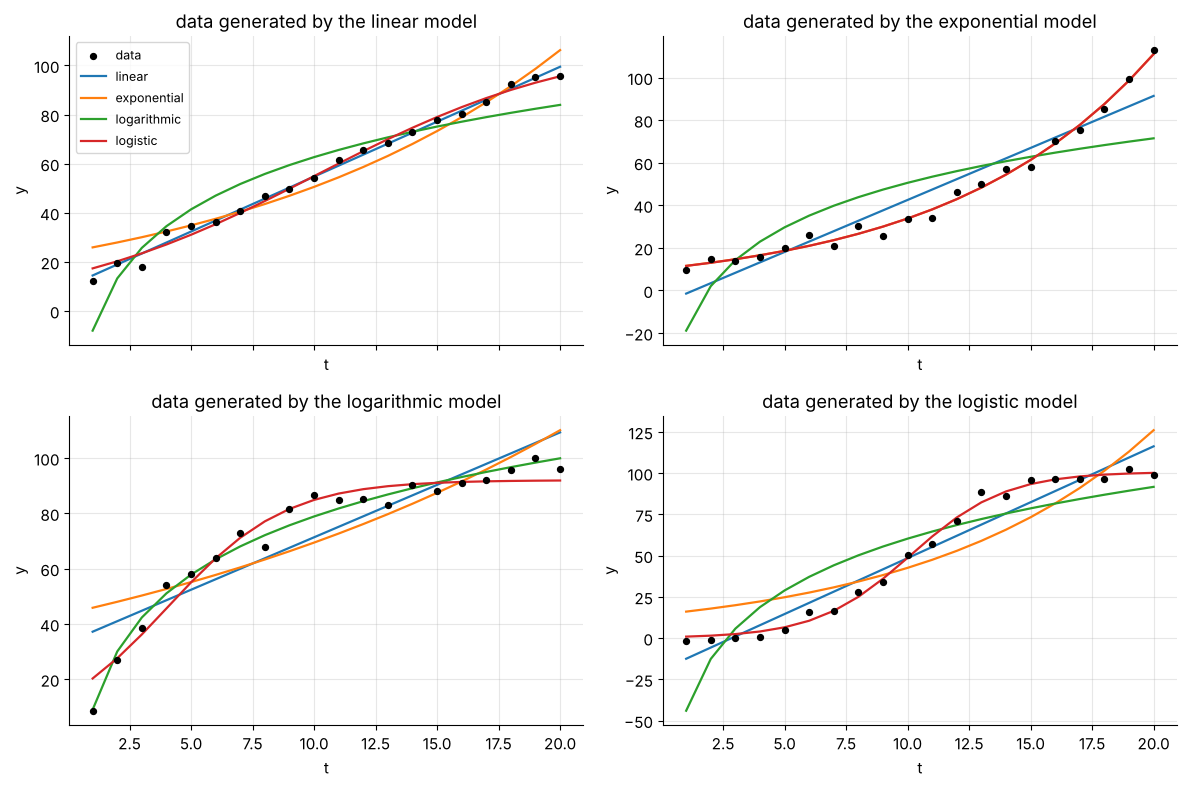

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, (true_name, yy) in zip(axes.ravel(), example_data.items()):
    fits = fit_all(tt, yy)
    ax.scatter(tt, yy, color="k", s=18, zorder=3, label="data")
    for model, res in fits.items():
        if res is None:
            continue
        f = TRUE[model][0]
        ax.plot(tt, f(tt, *res[0]), label=model, lw=1.6)
    ax.set_title(f"data generated by the {true_name} model")
    ax.set_xlabel("t")
    ax.set_ylabel("y")
axes[0, 0].legend(fontsize=9)
plt.tight_layout()
plt.show()

## 4. Simulation study: how often does model selection pick the right model?

We generate 200 datasets from each true model at two noise levels (additive, sd 3 and sd 10), fit all four models, and choose the one with the smallest AIC. The **confusion matrix** shows how often each true model was identified correctly. Rows are the true model, columns the model selected. Each row sums to 100%.

In [6]:
names = list(TRUE)

def run_study(noise_sd, n_sims=200):
    confusion = pd.DataFrame(0, index=names, columns=names, dtype=int)
    for true_name in names:
        f, params = TRUE[true_name]
        clean = f(tt, *params)
        for _ in range(n_sims):
            yy = clean + rng.normal(0, noise_sd, tt.size)
            fits = fit_all(tt, yy)
            scores = {m: aic(res[1], tt.size, res[2]) for m, res in fits.items() if res is not None}
            confusion.loc[true_name, min(scores, key=scores.get)] += 1
    return confusion

results = {}
for noise_sd in (3.0, 10.0):
    conf = run_study(noise_sd)
    results[noise_sd] = conf
    pct = (conf.div(conf.sum(axis=1), axis=0) * 100).round(0).astype(int)
    print(f"Noise sd = {noise_sd:g}: percentage of simulations in which each model was selected")
    print(pct.to_string())
    print(f"Overall correct identification: {np.trace(conf.values) / conf.values.sum():.1%}")
    print()

Noise sd = 3: percentage of simulations in which each model was selected
             linear  exponential  logarithmic  logistic
linear           86            0            0        14
exponential       0           93            0         7
logarithmic       0            0          100         0
logistic          0            0            0       100
Overall correct identification: 94.8%

Noise sd = 10: percentage of simulations in which each model was selected
             linear  exponential  logarithmic  logistic
linear           66           12            1        20
exponential       2           86            0        13
logarithmic       2            0           84        14
logistic          0            0            0       100
Overall correct identification: 84.0%



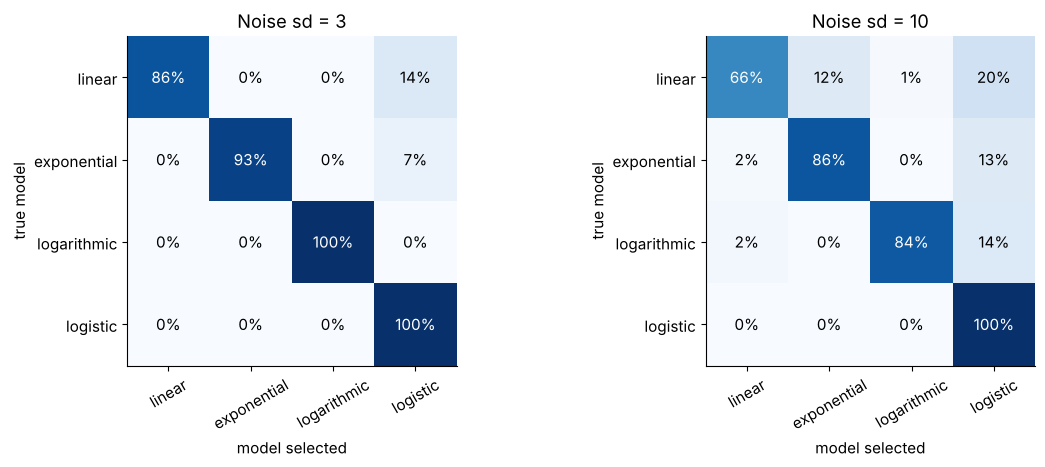

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (noise_sd, conf) in zip(axes, results.items()):
    pct = conf.div(conf.sum(axis=1), axis=0) * 100
    im = ax.imshow(pct.values, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(4), names, rotation=30)
    ax.set_yticks(range(4), names)
    ax.set_xlabel("model selected")
    ax.set_ylabel("true model")
    ax.set_title(f"Noise sd = {noise_sd:g}")
    ax.grid(False)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{pct.values[i, j]:.0f}%", ha="center", va="center",
                    color="white" if pct.values[i, j] > 55 else "black")
plt.tight_layout()
plt.show()

What to look for: accuracy falls as noise grows. Over the full window, the logistic model (the one with the extra parameter) is the one most often picked by mistake, and the linear model is the one most often missed. The next cell shows the effect of the **observation window**: we repeat the study using only the first 8 time points, which for the logistic and exponential models is the early, similar-looking part of the curve.

In [8]:
tt_full = tt.copy()
tt = np.arange(1, 9, dtype=float)             # only the early part of each curve
short = run_study(3.0, n_sims=100)
tt = tt_full                                   # restore the full window

pct_short = (short.div(short.sum(axis=1), axis=0) * 100).round(0).astype(int)
print("Window t = 1..8, noise sd = 3: percentage of simulations in which each model was selected")
print(pct_short.to_string())
print(f"Overall correct identification: {np.trace(short.values) / short.values.sum():.1%}")

Window t = 1..8, noise sd = 3: percentage of simulations in which each model was selected
             linear  exponential  logarithmic  logistic
linear           51           27            5        17
exponential      25           68            4         3
logarithmic       0            0           93         7
logistic          6           75            0        19
Overall correct identification: 57.8%


Compare with the full-window result at the same noise level: with only the early part of the curve, the models become much harder to tell apart, and data from the logistic model are mostly labelled as something else. This is the same message as in the logistic notebook: a limit is invisible until the curve starts to bend.

## 5. Using your own data

In [9]:
# import pandas as pd
# df = pd.read_csv("my_data.csv")                       # columns: t (> 0), y
# fits_own = fit_all(df["t"].to_numpy(float), df["y"].to_numpy(float))
# for model, res in fits_own.items():
#     if res is not None:
#         print(model, res[0], "AIC =", aic(res[1], len(df), res[2]))

## 6. Exercises

1. In section 3 change `sigma` to 1 and then to 15. Does the best model by AIC change?
2. In section 4 use a shorter window `tt = np.arange(1, 9, dtype=float)` and rerun. Which pairs of models are now confused most often?
3. Add a fifth candidate model, for example a quadratic $a + bt + ct^2$, and see which datasets it competes for.
4. Sketch, for each model, what you would expect a plot of $\Delta y$ against $t$ to look like. Check with code.
5. Real data rarely come from exactly one of these models. Collect a real dataset (for example the number of students who know a piece of news, or practice hours against a score) and decide which model fits best, and why.